# 03 数据探索与可视化模板复现

**本节完成内容**：探索性数据分析（EDA）+ 复现 16 种图表类型（fig01–fig14、fig25、fig26）。

| 图号 | 图表类型 | 数据口径 |
|---|---|---|
| fig01 | 柱状图 | 月度订单量 | 
| fig02 | 条形图（横向） | Top10 商品销售额 | 
| fig03 | 折线图 | 月度 GMV 走势 | 
| fig04 | 面积图 | 累计销售额 | 
| fig05 | 堆积面积图 | 三大品类月度销售 | 
| fig06 | 堆积柱状图 | 大区 × 品类 | 
| fig07 | 百分比堆积柱状图 | 细分市场 × 物流方式 | 
| fig08 | 饼图 | 品类销售占比 | 
| fig09 | 环形图 | 退货 vs 未退货 | 
| fig10 | 散点图 | 折扣 vs 利润率 | 
| fig11 | 气泡图 | 城市销售规模 | 
| fig12 | 箱线图 | 各大区利润率分布 | 
| fig13 | 热力图 | 州 × 月销售矩阵 | 
| fig14 | 雷达图 | 四大区多维对比 | 
| fig25 | 瀑布图 | 子类利润贡献分解 | 
| fig26 | 分组柱状图 | 各细分市场客单价对比 |

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.unicode.east_asian_width", True)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

COLORS = {"main": "#2E5C8A", "accent": "#E8743B", "green": "#4C9F70",
          "red": "#C0392B", "yellow": "#E4B363", "purple": "#6C5B7B", "gray": "#9AA0A6"}
PALETTE = [COLORS["main"], COLORS["accent"], COLORS["green"], COLORS["yellow"],
           COLORS["purple"], COLORS["red"], COLORS["gray"], "#4E79A7", "#76B7B2", "#F28E2B"]
CAT_COLORS = {"Furniture": COLORS["main"], "Office Supplies": COLORS["accent"], "Technology": COLORS["green"]}

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
CLEAN_DIR = ROOT / "data" / "clean"
FIG_DIR = ROOT / "outputs" / "figures"
TAB_DIR = ROOT / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)

fact = pd.read_csv(CLEAN_DIR / "fact_sales.csv", parse_dates=["Order Date", "Ship Date"])

def savefig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    return path

def kfmt(x, pos=None):
    if abs(x) >= 1e6:
        return "%.1fM" % (x / 1e6)
    if abs(x) >= 1e3:
        return "%.0fk" % (x / 1e3)
    return "%.0f" % x

print("数据规模：%d 行 × %d 列" % fact.shape)
print("时间范围：%s ~ %s" % (fact["Order Date"].min().date(), fact["Order Date"].max().date()))

数据规模：10194 行 × 38 列
时间范围：2023-01-03 ~ 2026-12-30


## 1. 数据探索性分析（EDA）

先看整体，再逐图复现。

In [2]:
eda = {
    "总销售额": round(fact["Sales"].sum(), 2),
    "总利润": round(fact["Profit"].sum(), 2),
    "整体利润率(%)": round(fact["Profit"].sum() / fact["Sales"].sum() * 100, 2),
    "订单数": fact["Order ID"].nunique(),
    "客户数": fact["Customer ID"].nunique(),
    "商品数": fact["Product ID"].nunique(),
    "客单价": round(fact["Sales"].sum() / fact["Order ID"].nunique(), 2),
    "平均折扣(%)": round(fact["Discount"].mean() * 100, 2),
    "平均发货天数": round(fact["Ship Days"].mean(), 2),
    "退货订单占比(%)": round(fact.loc[fact["Is Returned"] == 1, "Order ID"].nunique()
                            / fact["Order ID"].nunique() * 100, 2),
    "亏损明细行占比(%)": round((fact["Profit"] < 0).mean() * 100, 2),
}
pd.Series(eda).to_frame("指标值")

,指标值
总销售额,2326534.35
总利润,292296.81
整体利润率(%),12.56
订单数,5111.00
客户数,804.00
商品数,1862.00
客单价,455.20
平均折扣(%),15.54
平均发货天数,3.96
退货订单占比(%),5.79


In [3]:
cat = (fact.groupby("Category")
       .agg(销售额=("Sales", "sum"), 利润=("Profit", "sum"), 数量=("Quantity", "sum"),
            订单数=("Order ID", "nunique"), 平均折扣=("Discount", "mean"))
       .assign(利润率=lambda d: d["利润"] / d["销售额"] * 100,
               平均折扣=lambda d: d["平均折扣"] * 100)
       .round(2))
cat["销售额占比(%)"] = (cat["销售额"] / cat["销售额"].sum() * 100).round(1)
print(cat.to_string())

                    销售额       利润   数量  订单数  平均折扣  利润率  销售额占比(%)
Category                                                                             
Furniture        754747.76   19730.00   8369    1819     17.30    2.61           32.4
Office Supplies  731893.31  126023.44  23268    3812     15.63   17.22           31.5
Technology       839893.28  146543.38   7017    1560     13.15   17.45           36.1


In [4]:
#折扣与利润率的关系
bins = [-0.01, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
fact["折扣档"] = pd.cut(fact["Discount"], bins=bins)
disc = (fact.groupby("折扣档")
        .agg(明细行=("Row ID", "count"), 销售额=("Sales", "sum"), 利润=("Profit", "sum"))
        .assign(利润率=lambda d: (d["利润"] / d["销售额"] * 100).round(1)))
print(disc.to_string())
print("\n折扣 ≥ 40%% 的明细行：%d 行（占 %.1f%%），合计亏损 %.0f 美元" % (
    (fact["Discount"] >= 0.4).sum(), (fact["Discount"] >= 0.4).mean() * 100,
    fact.loc[fact["Discount"] >= 0.4, "Profit"].sum()))

              明细行        销售额         利润  利润率
折扣档                                                 
(-0.01, 0.0]    4925  1.105324e+06  326718.5872    29.6
(0.0, 0.1]        96  5.495250e+04    9099.9700    16.6
(0.1, 0.2]      3758  8.014979e+05   92498.9432    11.5
(0.2, 0.3]       230  1.044741e+05  -10513.4456   -10.1
(0.3, 0.4]       234  1.309912e+05  -25477.5119   -19.4
(0.4, 0.5]        77  6.440351e+04  -22999.5392   -35.7
(0.5, 0.6]       149  7.105940e+03   -6164.3472   -86.7
(0.6, 0.7]       424  4.080527e+04  -40300.5727   -98.8
(0.7, 0.8]       301  1.698015e+04  -30565.2692  -180.0

折扣 ≥ 40% 的明细行：1158 行（占 11.4%），合计亏损 -123116 美元


**EDA结果**
1. **规模**：4 年累计 GMV 232.65 万美元、利润 29.23 万美元，整体利润率仅 12.56%——零售薄利特征明显；
2. **结构错位**：Office Supplies 占大部分明细行，却只贡献 31.5% 的销售额（客单低、件数多）；Technology 以 36.1% 的销售额贡献 17.4% 的利润率，是真正的利润引擎；Furniture 销售额占 32.4%，利润率只有 2.6%（被高折扣的 Tables、Bookcases 拖累）；
3. **折扣是亏损的第一驱动**：无折扣订单利润率 30%，10%–20% 折扣降到 12%，20%–30% 折扣已变成 −10%，40% 以上深折扣长期为负（−36% 至 −180%），"深折扣换量"在这门生意里并不成立；
4. **区域分化**：West 利润率 14.98%、East 13.71%、South 11.93%，而 Central 只有 7.92%，同样的折扣政策在 Central 明显更"伤"；
5. **履约**：平均发货 3.96 天，退货率 5.79%，二者与利润的关系将在后面的漏斗图中展开。

## 2. 模板复现

### fig01 柱状图：月度订单量

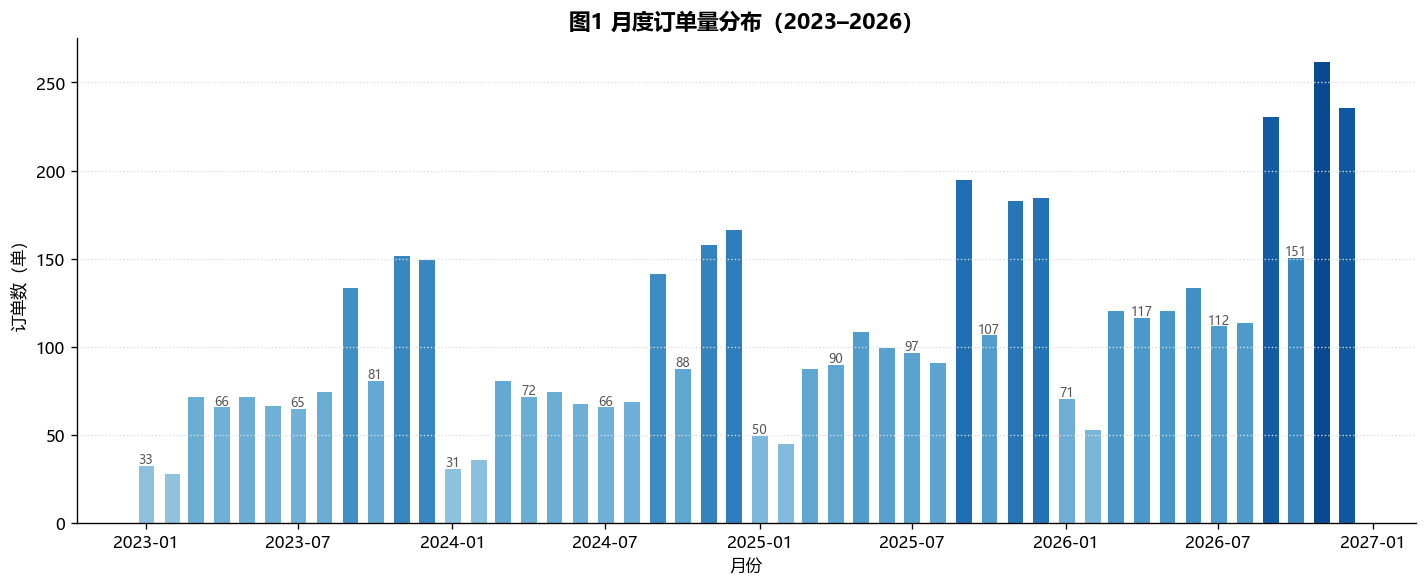

In [5]:
m_orders = fact.groupby("YearMonth")["Order ID"].nunique().reset_index()
m_orders["月份"] = pd.PeriodIndex(m_orders["YearMonth"], freq="M").to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
norm = m_orders["Order ID"] / m_orders["Order ID"].max()
bars = ax.bar(m_orders["月份"], m_orders["Order ID"], width=20,
              color=[plt.cm.Blues(0.35 + 0.55 * v) for v in norm], edgecolor="white", lw=0.6)
for i, (b, v) in enumerate(zip(bars, m_orders["Order ID"])):
    if i % 3 == 0:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, str(v),
                ha="center", fontsize=7.5, color="#555555")
ax.set_title("图1 月度订单量分布（2023–2026）")
ax.set_xlabel("月份")
ax.set_ylabel("订单数（单）")
ax.grid(axis="y", ls=":", color="#DDDDDD")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig(fig, "fig01_月度订单量柱状图.png")
plt.show()

### fig02 条形图：Top10 商品销售额

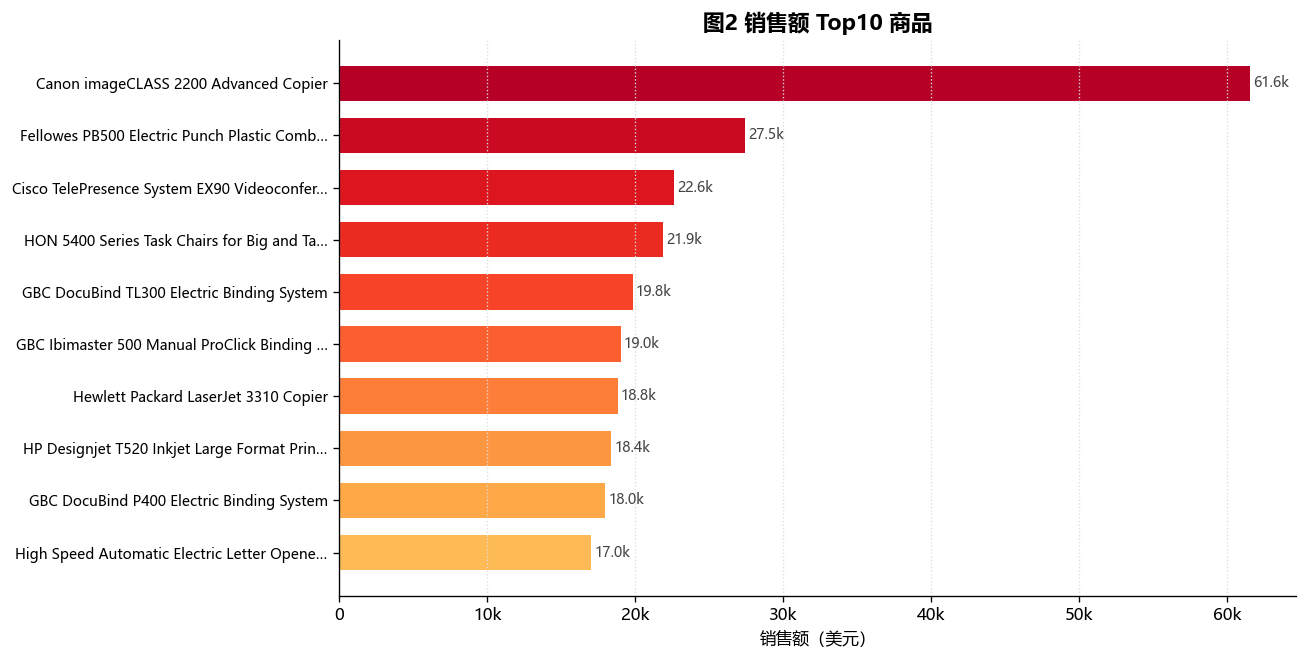

In [6]:
top10 = (fact.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
         .sort_values())
fig, ax = plt.subplots(figsize=(11, 5.6))
bars = ax.barh(range(len(top10)), top10.values, color=[plt.cm.YlOrRd(0.35 + 0.06 * i) for i in range(len(top10))],
               height=0.68)
ax.set_yticks(range(len(top10)))
ax.set_yticklabels([n[:42] + ("…" if len(n) > 42 else "") for n in top10.index], fontsize=8.5)
for i, v in enumerate(top10.values):
    ax.text(v + 200, i, "%.1fk" % (v / 1000), va="center", fontsize=8.5, color="#444444")
ax.set_xlabel("销售额（美元）")
ax.set_title("图2 销售额 Top10 商品")
ax.xaxis.set_major_formatter(FuncFormatter(kfmt))
ax.grid(axis="x", ls=":", color="#DDDDDD")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig(fig, "fig02_Top10商品销售额条形图.png")
plt.show()

### fig03 折线图：月度 GMV 走势

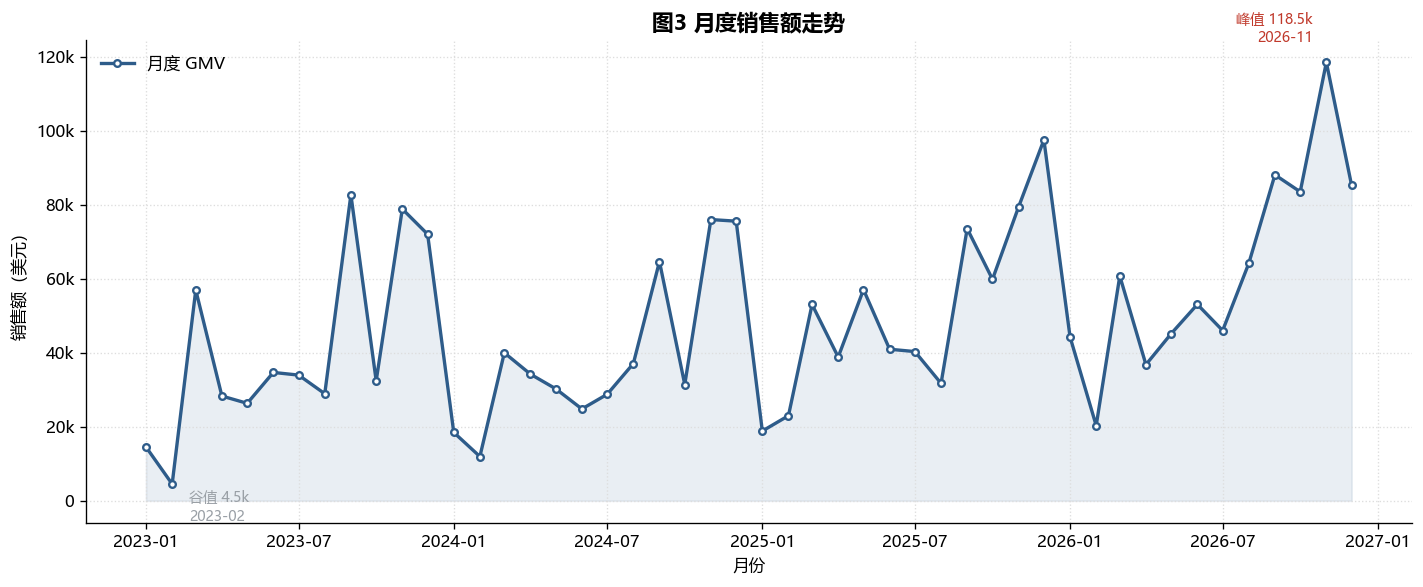

In [7]:
m = fact.groupby("YearMonth")["Sales"].sum().reset_index()
m["月份"] = pd.PeriodIndex(m["YearMonth"], freq="M").to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(m["月份"], m["Sales"], color=COLORS["main"], lw=2, marker="o", ms=4, mfc="white", mew=1.4, label="月度 GMV")
ax.fill_between(m["月份"], m["Sales"], color=COLORS["main"], alpha=0.10)
imax, imin = m["Sales"].idxmax(), m["Sales"].idxmin()
ax.annotate("峰值 %.1fk\n%s" % (m.loc[imax, "Sales"] / 1000, m.loc[imax, "YearMonth"]),
            (m.loc[imax, "月份"], m.loc[imax, "Sales"]), textcoords="offset points", xytext=(-8, 12),
            fontsize=8.5, color=COLORS["red"], ha="right")
ax.annotate("谷值 %.1fk\n%s" % (m.loc[imin, "Sales"] / 1000, m.loc[imin, "YearMonth"]),
            (m.loc[imin, "月份"], m.loc[imin, "Sales"]), textcoords="offset points", xytext=(10, -22),
            fontsize=8.5, color=COLORS["gray"])
ax.set_title("图3 月度销售额走势")
ax.set_xlabel("月份")
ax.set_ylabel("销售额（美元）")
ax.yaxis.set_major_formatter(FuncFormatter(kfmt))
ax.legend(frameon=False, loc="upper left")
ax.grid(ls=":", color="#DDDDDD")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig(fig, "fig03_月度销售额折线图.png")
plt.show()

### fig04 面积图：累计销售额

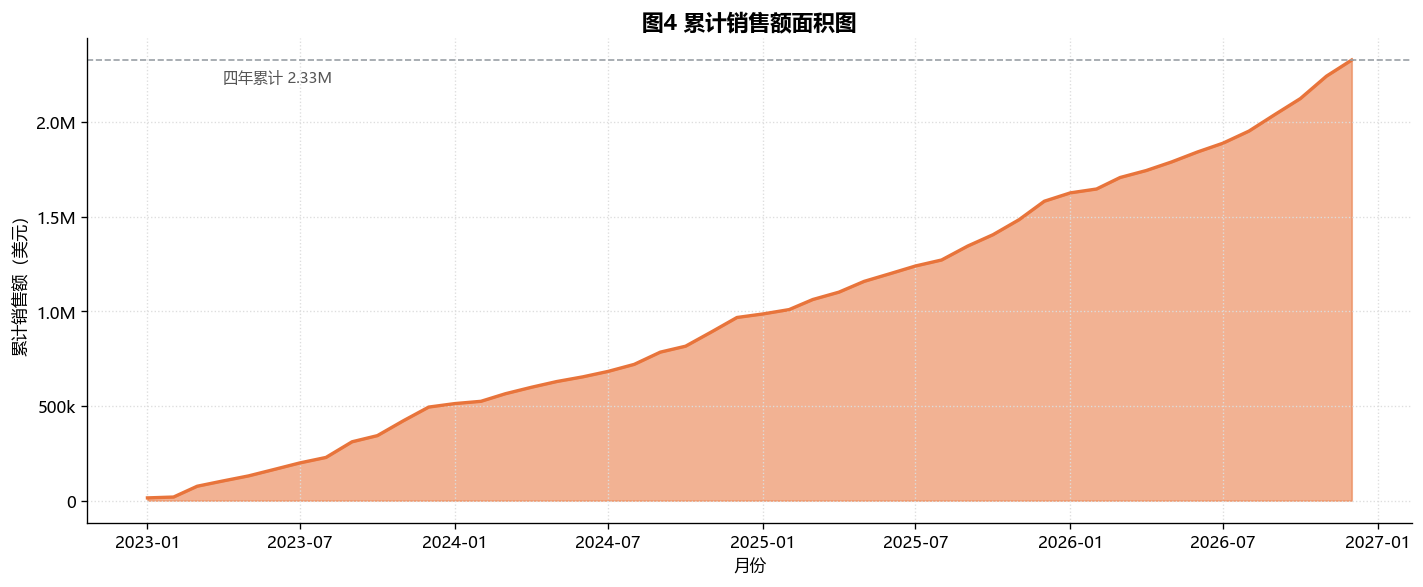

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(m["月份"], m["Sales"].cumsum(), color=COLORS["accent"], alpha=0.55, label="累计销售额")
ax.plot(m["月份"], m["Sales"].cumsum(), color=COLORS["accent"], lw=2)
ax.axhline(m["Sales"].sum(), color=COLORS["gray"], ls="--", lw=1)
ax.text(m["月份"].iloc[3], m["Sales"].sum() * 0.95, "四年累计 %.2fM" % (m["Sales"].sum() / 1e6),
        fontsize=9, color="#555555")
ax.set_title("图4 累计销售额面积图")
ax.set_xlabel("月份")
ax.set_ylabel("累计销售额（美元）")
ax.yaxis.set_major_formatter(FuncFormatter(kfmt))
ax.grid(ls=":", color="#DDDDDD")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig(fig, "fig04_累计销售额面积图.png")
plt.show()

### fig05 堆积面积图：三大品类月度销售

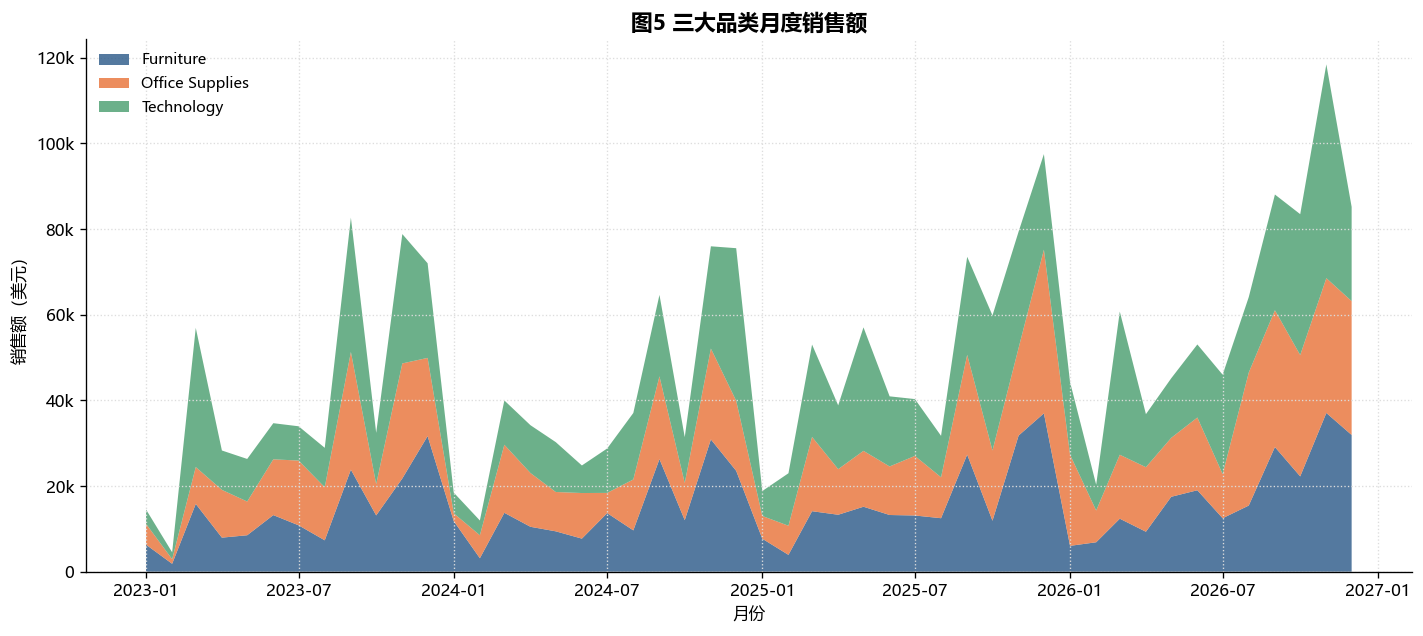

In [9]:
pivot_cat = fact.pivot_table(index="YearMonth", columns="Category", values="Sales", aggfunc="sum").fillna(0)
pivot_cat.index = pd.PeriodIndex(pivot_cat.index, freq="M").to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5.4))
ax.stackplot(pivot_cat.index, [pivot_cat[c] for c in pivot_cat.columns],
             labels=list(pivot_cat.columns),
             colors=[CAT_COLORS[c] for c in pivot_cat.columns], alpha=0.82)
ax.set_title("图5 三大品类月度销售额")
ax.set_xlabel("月份")
ax.set_ylabel("销售额（美元）")
ax.yaxis.set_major_formatter(FuncFormatter(kfmt))
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.grid(ls=":", color="#DDDDDD")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig(fig, "fig05_品类月度堆积面积图.png")
plt.show()

### fig06 堆积柱状图：大区 × 品类

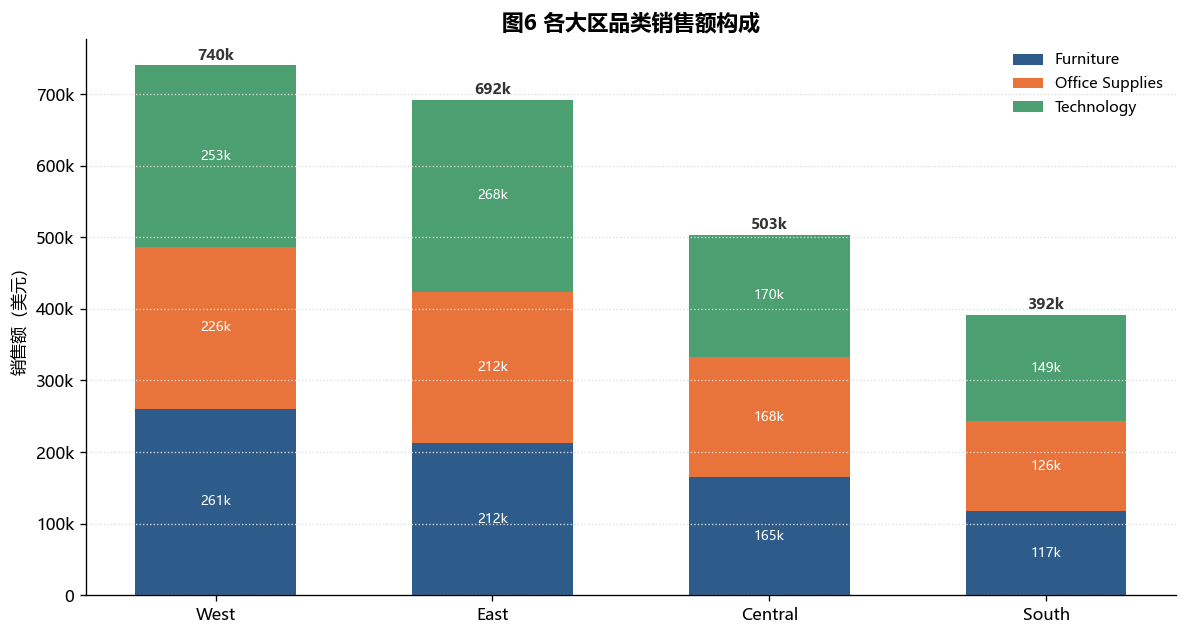

In [10]:
pivot_rc = fact.pivot_table(index="Region", columns="Category", values="Sales", aggfunc="sum").fillna(0)
pivot_rc = pivot_rc.loc[pivot_rc.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 5.4))
bottom = np.zeros(len(pivot_rc))
for c in pivot_rc.columns:
    ax.bar(pivot_rc.index, pivot_rc[c], bottom=bottom, label=c, color=CAT_COLORS[c], width=0.58)
    for i, (v, b) in enumerate(zip(pivot_rc[c], bottom)):
        if v / pivot_rc.sum(axis=1).max() > 0.04:
            ax.text(i, b + v / 2, "%.0fk" % (v / 1000), ha="center", va="center",
                    fontsize=8, color="white")
    bottom += pivot_rc[c].values
for i, t in enumerate(pivot_rc.sum(axis=1)):
    ax.text(i, t + 8000, "%.0fk" % (t / 1000), ha="center", fontsize=9, fontweight="bold", color="#333333")
ax.set_title("图6 各大区品类销售额构成")
ax.set_ylabel("销售额（美元）")
ax.yaxis.set_major_formatter(FuncFormatter(kfmt))
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.grid(axis="y", ls=":", color="#DDDDDD")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig(fig, "fig06_大区品类堆积柱状图.png")
plt.show()

### fig07 百分比堆积柱状图：细分市场 × 物流方式

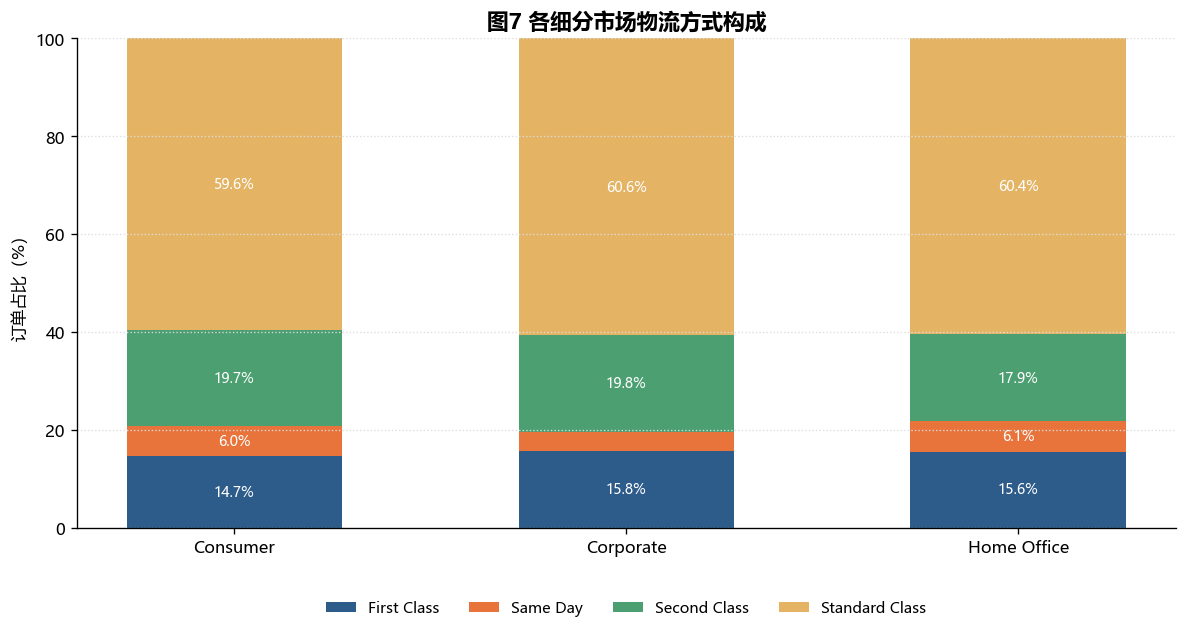

In [11]:
pivot_sm = fact.pivot_table(index="Segment", columns="Ship Mode", values="Row ID", aggfunc="count").fillna(0)
pivot_pct = pivot_sm.div(pivot_sm.sum(axis=1), axis=0) * 100
pivot_pct = pivot_pct.loc[pivot_pct.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 5.4))
bottom = np.zeros(len(pivot_pct))
ship_colors = [COLORS["main"], COLORS["accent"], COLORS["green"], COLORS["yellow"]]
for i, c in enumerate(pivot_pct.columns):
    vals = pivot_pct[c].values
    ax.bar(pivot_pct.index, vals, bottom=bottom, label=c, color=ship_colors[i % 4], width=0.55)
    for j, (v, b) in enumerate(zip(vals, bottom)):
        if v > 6:
            ax.text(j, b + v / 2, "%.1f%%" % v, ha="center", va="center", fontsize=8.5, color="white")
    bottom += vals
ax.set_ylim(0, 100)
ax.set_ylabel("订单占比（%）")
ax.set_title("图7 各细分市场物流方式构成")
ax.legend(frameon=False, ncol=4, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="y", ls=":", color="#DDDDDD")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig(fig, "fig07_细分市场物流方式百分比堆积图.png")
plt.show()

### fig08 饼图：品类销售占比

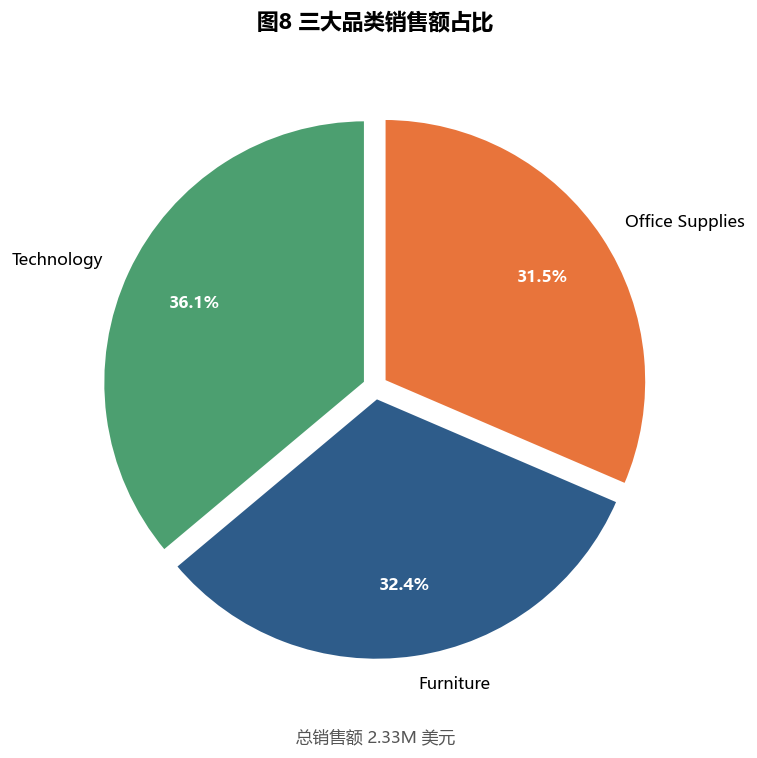

In [12]:
cat_sum = fact.groupby("Category")["Sales"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7.6, 6.4))
explode = [0.04] * len(cat_sum)
wedges, texts, autotexts = ax.pie(cat_sum.values, labels=cat_sum.index, autopct="%.1f%%",
                                  startangle=90, explode=explode,
                                  colors=[CAT_COLORS[c] for c in cat_sum.index],
                                  textprops={"fontsize": 10}, pctdistance=0.72,
                                  wedgeprops={"edgecolor": "white", "linewidth": 2})
for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
ax.set_title("图8 三大品类销售额占比", pad=18)
ax.text(0, -1.35, "总销售额 %.2fM 美元" % (cat_sum.sum() / 1e6), ha="center", fontsize=10, color="#555555")
plt.tight_layout()
savefig(fig, "fig08_品类销售占比饼图.png")
plt.show()

### fig09 环形图：退货订单占比

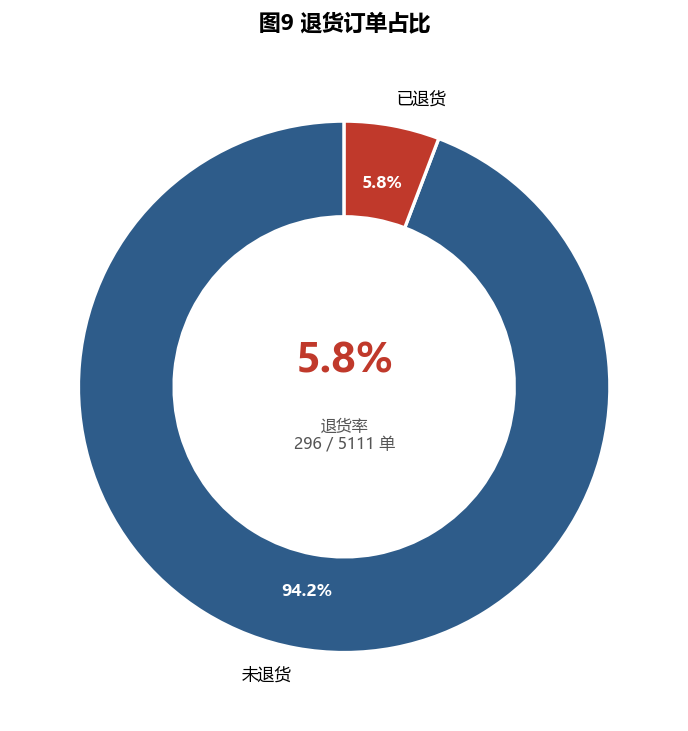

In [13]:
orders_n = fact["Order ID"].nunique()
ret_n = fact.loc[fact["Is Returned"] == 1, "Order ID"].nunique()
vals = [orders_n - ret_n, ret_n]
fig, ax = plt.subplots(figsize=(6.8, 6.2))
wedges, texts, autotexts = ax.pie(vals, labels=["未退货", "已退货"], autopct="%1.1f%%",
                                  colors=[COLORS["main"], COLORS["red"]], startangle=90,
                                  wedgeprops=dict(width=0.36, edgecolor="white", linewidth=2),
                                  textprops={"fontsize": 10}, pctdistance=0.78)
for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
ax.text(0, 0.10, "%.1f%%" % (ret_n / orders_n * 100), ha="center", va="center",
        fontsize=24, fontweight="bold", color=COLORS["red"])
ax.text(0, -0.18, "退货率\n%d / %d 单" % (ret_n, orders_n), ha="center", va="center",
        fontsize=9.5, color="#555555")
ax.set_title("图9 退货订单占比", pad=16)
plt.tight_layout()
savefig(fig, "fig09_退货订单环形图.png")
plt.show()

### fig10 散点图：折扣 vs 利润率

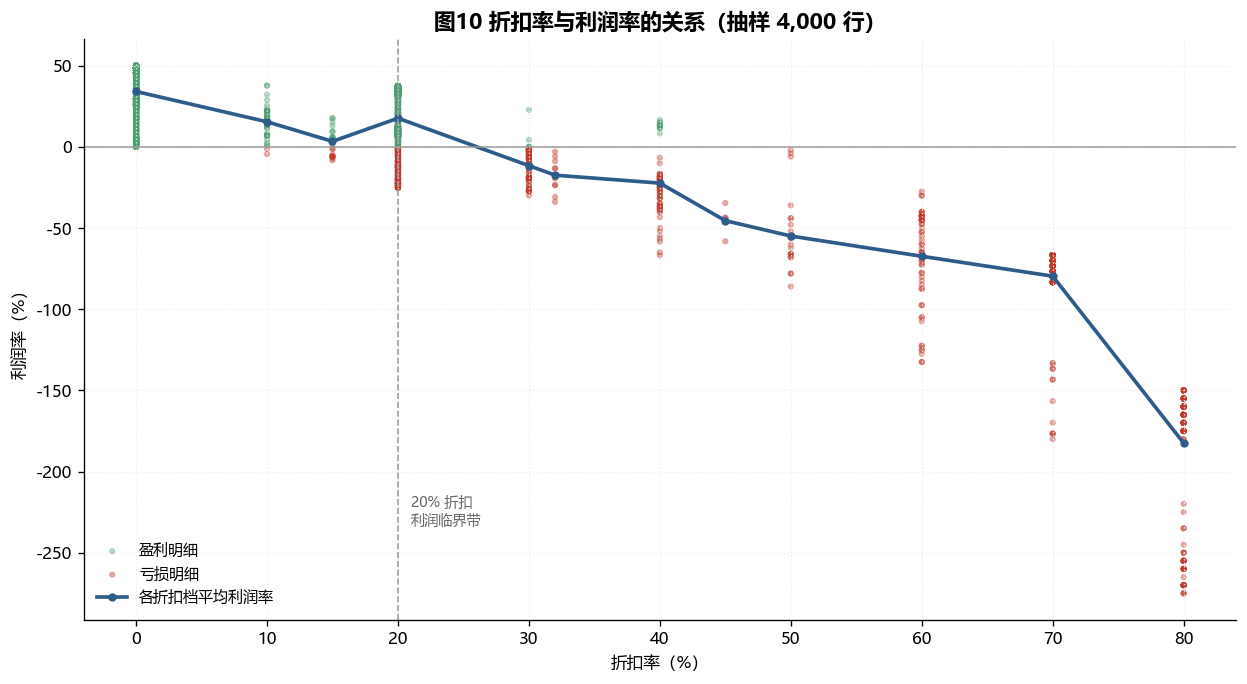

In [14]:
sample = fact.sample(n=min(4000, len(fact)), random_state=RANDOM_SEED)
fig, ax = plt.subplots(figsize=(10.5, 5.8))
pos = sample[sample["Profit"] >= 0]
neg = sample[sample["Profit"] < 0]
ax.scatter(pos["Discount"] * 100, pos["Profit Margin"] * 100, s=14, color=COLORS["green"], alpha=0.45, label="盈利明细", edgecolor="none")
ax.scatter(neg["Discount"] * 100, neg["Profit Margin"] * 100, s=14, color=COLORS["red"], alpha=0.45, label="亏损明细", edgecolor="none")
# 分档均值折线：展示趋势
g = fact.groupby("Discount")["Profit Margin"].mean() * 100
ax.plot(g.index * 100, g.values, color=COLORS["main"], lw=2.2, marker="o", ms=4, label="各折扣档平均利润率")
ax.axhline(0, color="#999999", lw=0.9)
ax.axvline(20, color=COLORS["gray"], ls="--", lw=1)
ax.text(21, ax.get_ylim()[0] * 0.8, "20% 折扣\n利润临界带", fontsize=8.5, color="#666666")
ax.set_xlabel("折扣率（%）")
ax.set_ylabel("利润率（%）")
ax.set_title("图10 折扣率与利润率的关系（抽样 4,000 行）")
ax.legend(frameon=False, fontsize=9, loc="lower left")
ax.grid(ls=":", color="#EEEEEE")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig(fig, "fig10_折扣与利润率散点图.png")
plt.show()

In [15]:
corr = fact[["Discount", "Profit Margin", "Sales", "Quantity"]].corr().round(3)
print("相关系数矩阵：")
print(corr.to_string())
print("\n结论：折扣与利润率相关系数 %.2f，强负相关。" % corr.loc["Discount", "Profit Margin"])

相关系数矩阵：
               Discount  Profit Margin  Sales  Quantity
Discount          1.000         -0.865 -0.028     0.007
Profit Margin    -0.865          1.000  0.003    -0.004
Sales            -0.028          0.003  1.000     0.198
Quantity          0.007         -0.004  0.198     1.000

结论：折扣与利润率相关系数 -0.86，强负相关。


### fig11 气泡图：城市销售规模

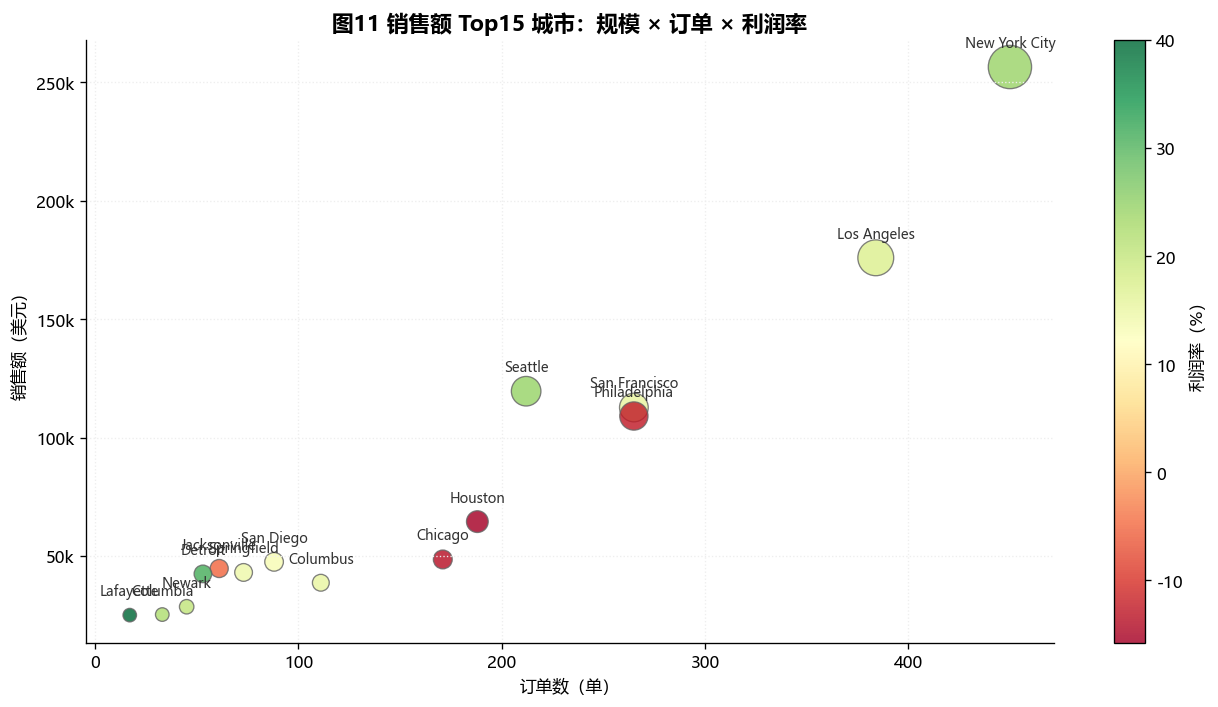

In [16]:
city = (fact.groupby("City")
        .agg(销售额=("Sales", "sum"), 订单数=("Order ID", "nunique"), 利润=("Profit", "sum"))
        .reset_index())
city["利润率(%)"] = city["利润"] / city["销售额"] * 100
top_city = city.nlargest(15, "销售额")

fig, ax = plt.subplots(figsize=(11, 6))
sc = ax.scatter(top_city["订单数"], top_city["销售额"], s=top_city["销售额"] / 380,
                c=top_city["利润率(%)"], cmap="RdYlGn", alpha=0.82, edgecolor="#666666", lw=0.8)
cb = plt.colorbar(sc, ax=ax)
cb.set_label("利润率（%）", fontsize=10)
for _, r in top_city.iterrows():
    ax.annotate(r["City"], (r["订单数"], r["销售额"]), textcoords="offset points",
                xytext=(0, 12), ha="center", fontsize=8.2, color="#333333")
ax.set_xlabel("订单数（单）")
ax.set_ylabel("销售额（美元）")
ax.set_title("图11 销售额 Top15 城市：规模 × 订单 × 利润率")
ax.yaxis.set_major_formatter(FuncFormatter(kfmt))
ax.grid(ls=":", color="#EEEEEE")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig(fig, "fig11_城市销售气泡图.png")
plt.show()

### fig12 箱线图：各大区利润率分布

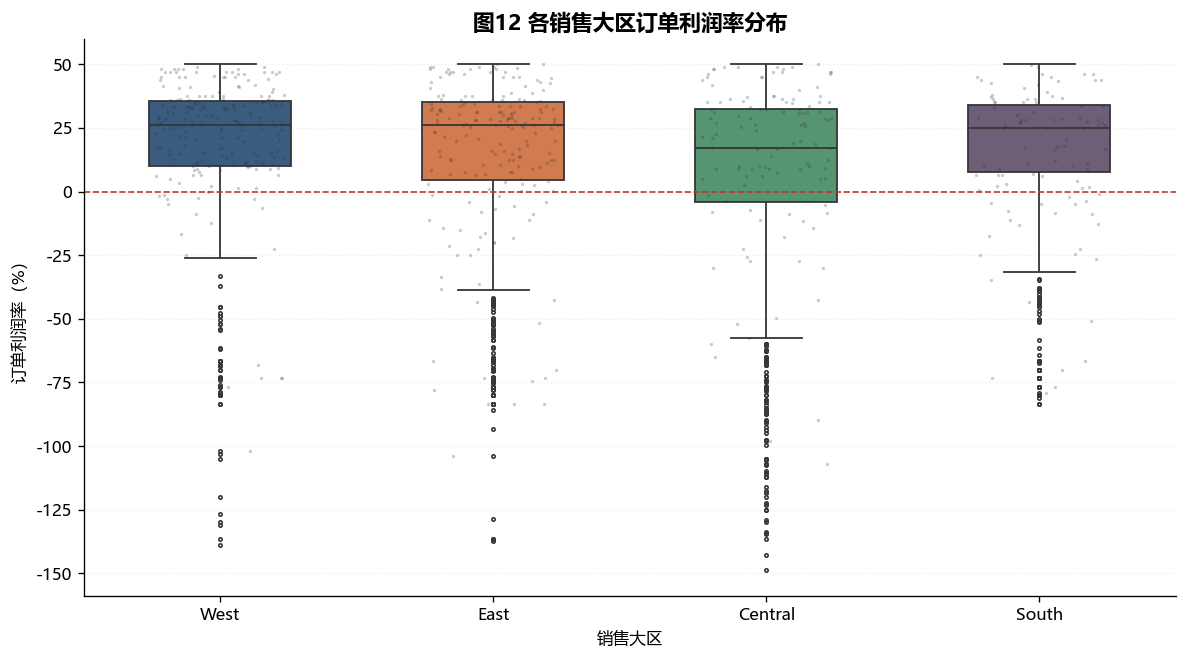

In [17]:
order_df = (fact.groupby(["Order ID", "Region"])
            .agg(销售额=("Sales", "sum"), 利润=("Profit", "sum"))
            .reset_index())
order_df["利润率(%)"] = order_df["利润"] / order_df["销售额"] * 100
order_df = order_df[(order_df["利润率(%)"] > -150) & (order_df["利润率(%)"] < 150)]   # 去除极端值便于观察分布

fig, ax = plt.subplots(figsize=(10, 5.6))
sns.boxplot(x="Region", y="利润率(%)", data=order_df, ax=ax, width=0.52,
            palette=[COLORS["main"], COLORS["accent"], COLORS["green"], COLORS["purple"]],
            fliersize=2, linewidth=1.1)
sns.stripplot(x="Region", y="利润率(%)", data=order_df.sample(600, random_state=RANDOM_SEED),
              ax=ax, size=2, color="#333333", alpha=0.25, jitter=0.24)
ax.axhline(0, color=COLORS["red"], ls="--", lw=1)
ax.set_xlabel("销售大区")
ax.set_ylabel("订单利润率（%）")
ax.set_title("图12 各销售大区订单利润率分布")
ax.grid(axis="y", ls=":", color="#EEEEEE")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig(fig, "fig12_大区利润率箱线图.png")
plt.show()

### fig13 热力图：州 × 月销售矩阵

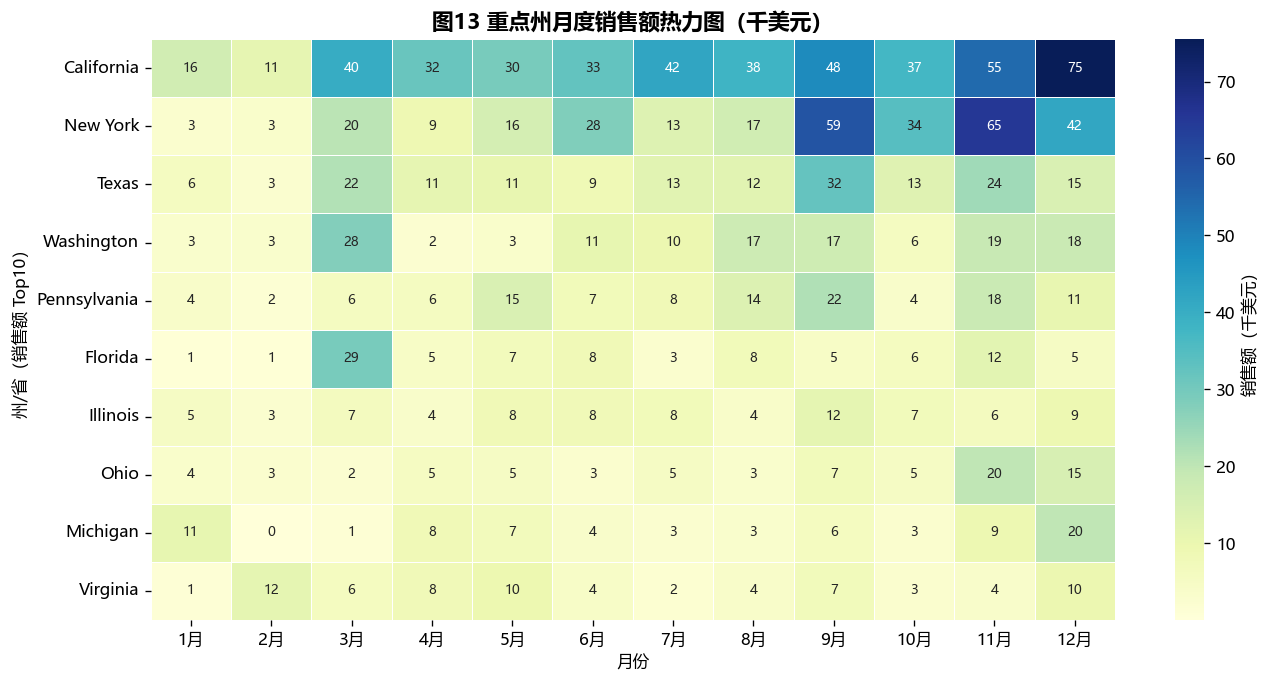

In [18]:
top_state = fact.groupby("State/Province")["Sales"].sum().nlargest(10).index
hm = (fact[fact["State/Province"].isin(top_state)]
      .pivot_table(index="State/Province", columns="Month", values="Sales", aggfunc="sum")
      .reindex(top_state))
hm.columns = ["%d月" % c for c in hm.columns]

fig, ax = plt.subplots(figsize=(11.5, 5.8))
sns.heatmap(hm / 1000, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax,
            cbar_kws={"label": "销售额（千美元）"}, linewidths=0.5, linecolor="white",
            annot_kws={"fontsize": 8})
ax.set_xlabel("月份")
ax.set_ylabel("州/省（销售额 Top10）")
ax.set_title("图13 重点州月度销售额热力图（千美元）")
plt.tight_layout()
savefig(fig, "fig13_州月度销售热力图.png")
plt.show()

### fig14 雷达图：四大区多维对比

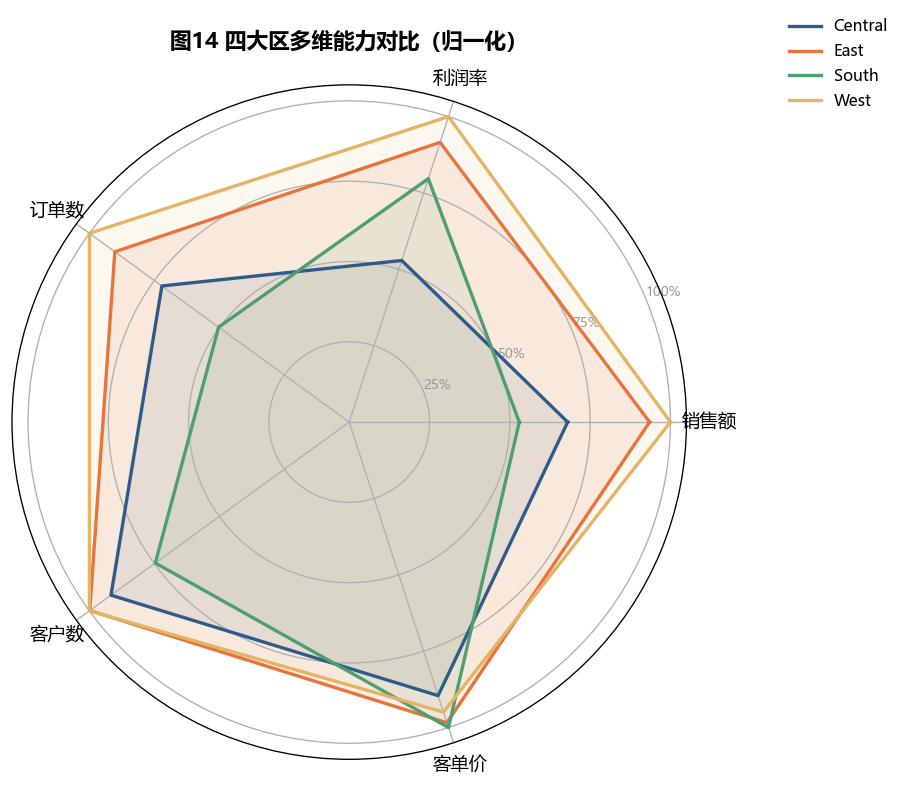

In [19]:
reg = (fact.groupby("Region")
       .agg(销售额=("Sales", "sum"), 利润=("Profit", "sum"), 订单数=("Order ID", "nunique"),
            客户数=("Customer ID", "nunique"), 发货天数=("Ship Days", "mean")))
reg["利润率"] = reg["利润"] / reg["销售额"] * 100
reg["客单价"] = reg["销售额"] / reg["订单数"]
dims = ["销售额", "利润率", "订单数", "客户数", "客单价"]
radar = reg[dims].copy()
for c in dims:
    radar[c] = radar[c] / radar[c].max()

labels = ["销售额", "利润率", "订单数", "客户数", "客单价"]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7.6, 6.6), subplot_kw=dict(polar=True))
for i, (name, row) in enumerate(radar.iterrows()):
    vals = row.tolist() + [row.tolist()[0]]
    ax.plot(angles, vals, lw=2, color=PALETTE[i], label=name)
    ax.fill(angles, vals, color=PALETTE[i], alpha=0.10)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylim(0, 1.05)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(["25%", "50%", "75%", "100%"], fontsize=8, color="#999999")
ax.set_title("图14 四大区多维能力对比（归一化）", pad=22)
ax.legend(loc="upper right", bbox_to_anchor=(1.32, 1.12), frameon=False, fontsize=9.5)
plt.tight_layout()
savefig(fig, "fig14_大区多维雷达图.png")
plt.show()

### fig25 瀑布图：子类利润贡献分解

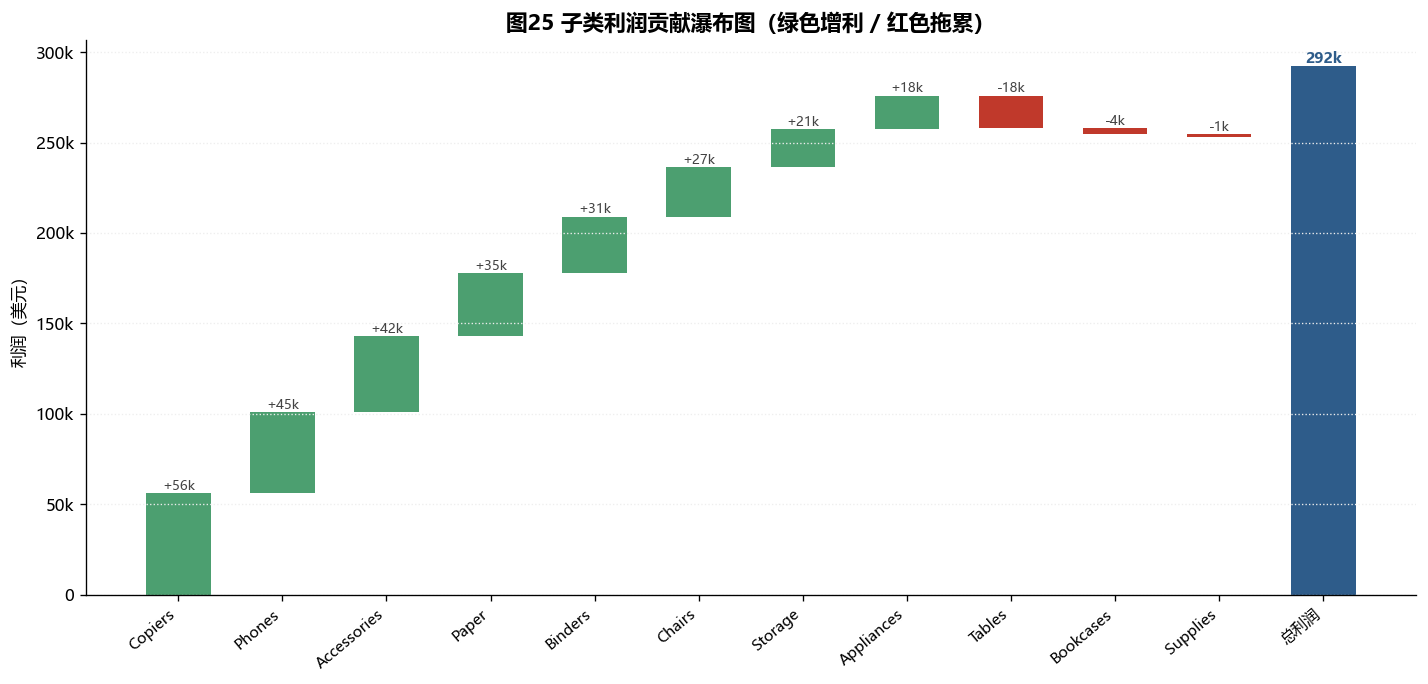

In [20]:
profit_by_sub = (fact.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False))
pos = profit_by_sub[profit_by_sub >= 0].head(8)
neg = profit_by_sub[profit_by_sub < 0].sort_values()
items = list(pos.index) + list(neg.index)
vals = list(pos.values) + list(neg.values)

cum = np.concatenate([[0], np.cumsum(vals)])
fig, ax = plt.subplots(figsize=(12, 5.8))
for i, (name, v) in enumerate(zip(items, vals)):
    bottom = cum[i] if v >= 0 else cum[i + 1]
    ax.bar(i, abs(v), bottom=bottom, color=COLORS["green"] if v >= 0 else COLORS["red"], width=0.62)
    ax.text(i, bottom + abs(v) + 1800, "%+.0fk" % (v / 1000), ha="center", fontsize=8, color="#444444")
ax.bar(len(items), profit_by_sub.sum(), color=COLORS["main"], width=0.62)
ax.text(len(items), profit_by_sub.sum() + 1800, "%.0fk" % (profit_by_sub.sum() / 1000),
        ha="center", fontsize=9, fontweight="bold", color=COLORS["main"])
ax.set_xticks(range(len(items) + 1))
ax.set_xticklabels(items + ["总利润"], rotation=40, ha="right", fontsize=9)
ax.set_ylabel("利润（美元）")
ax.yaxis.set_major_formatter(FuncFormatter(kfmt))
ax.set_title("图25 子类利润贡献瀑布图（绿色增利 / 红色拖累）")
ax.grid(axis="y", ls=":", color="#EEEEEE")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig(fig, "fig25_子类利润贡献瀑布图.png")
plt.show()

### fig26 分组柱状图：各细分市场客单价与利润率

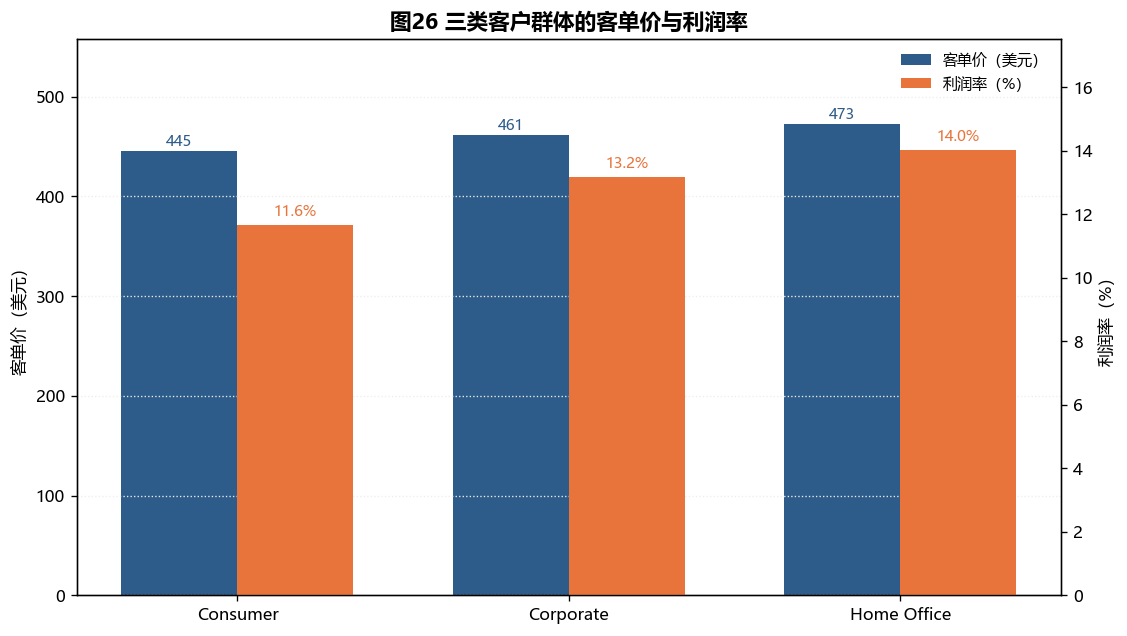

In [21]:
segstat = (fact.groupby("Segment")
           .agg(销售额=("Sales", "sum"), 订单数=("Order ID", "nunique"), 利润=("Profit", "sum")))
segstat["客单价"] = segstat["销售额"] / segstat["订单数"]
segstat["利润率(%)"] = segstat["利润"] / segstat["销售额"] * 100

fig, ax1 = plt.subplots(figsize=(9.5, 5.4))
x = np.arange(len(segstat))
w = 0.35
b1 = ax1.bar(x - w / 2, segstat["客单价"], width=w, color=COLORS["main"], label="客单价（美元）")
ax2 = ax1.twinx()
b2 = ax2.bar(x + w / 2, segstat["利润率(%)"], width=w, color=COLORS["accent"], label="利润率（%）")
for b in b1:
    ax1.text(b.get_x() + b.get_width() / 2, b.get_height() + 5, "%.0f" % b.get_height(), ha="center", fontsize=9, color=COLORS["main"])
for b in b2:
    ax2.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, "%.1f%%" % b.get_height(), ha="center", fontsize=9, color=COLORS["accent"])
ax1.set_xticks(x)
ax1.set_xticklabels(segstat.index)
ax1.set_ylabel("客单价（美元）")
ax2.set_ylabel("利润率（%）")
ax1.set_ylim(0, segstat["客单价"].max() * 1.18)
ax2.set_ylim(0, segstat["利润率(%)"].max() * 1.25)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, frameon=False, fontsize=9, loc="upper right")
ax1.set_title("图26 三类客户群体的客单价与利润率")
ax1.grid(axis="y", ls=":", color="#EEEEEE")
plt.tight_layout()
savefig(fig, "fig26_细分市场客单价分组柱状图.png")
plt.show()

In [22]:
print(segstat.round(2).to_string())

                 销售额  订单数       利润  客单价  利润率(%)
Segment                                                      
Consumer     1170659.79    2628  136371.45  445.46      11.65
Corporate     715806.13    1552   94249.64  461.22      13.17
Home Office   440068.43     931   61675.73  472.68      14.02


## 小结
1. **规模在涨、利润没跟上**：GMV 四年连续增长（2026 年同比 +21.4%），但整体利润率长期停在 12%–13%，增长质量不高；
2. **折扣是利润的"开关"**：散点图与分档均值都显示，折扣从 20% 起利润率转负，40% 以上几乎必亏——这是后续定价建议的直接依据；
3. **区域差异明显**：West 与 East 贡献主要销售额且利润率最高（15.0%、13.7%），Central 的订单利润率分布最靠下（7.9%），促销政策需要分区域差异化；
4. **品类结构错位**：销售额最大的 Technology 利润率最高，而次数最多的 Office Supplies 客单最低，说明"多 SKU、低单价"的运营模式需要向"少 SKU、高连带"改造。